# Ứng dụng AI vào Quản trị Vận hành
## Phân tích quy trình bằng Process Mining — Ví dụ: Quy trình cấp mã khuyến mãi

*Kính chào thầy/cô và các bạn. Sau đây nhóm em xin trình bày đề tài **ứng dụng AI vào quản trị vận hành**.*

**Thời lượng:** ~20 phút &nbsp;|&nbsp; **Công cụ nhóm em dùng:** Python · pandas · PM4Py · matplotlib/seaborn

---

### Nội dung tụi em sẽ trình bày (7 phần)

| # | Phần | Nội dung chính | Thời lượng |
|---|------|----------|-----------|
| 1 | **Bối cảnh & Mục tiêu** | Vấn đề đang gặp, câu hỏi nhóm em muốn trả lời | 2' |
| 2 | **Dữ liệu & Cách làm** | Dữ liệu nhật ký, công cụ Process Mining | 2' |
| 3 | **Quy trình hiện tại (AS-IS)** | Bản đồ quy trình, tìm điểm nghẽn | 4' |
| 4 | **Đo hiệu quả** | Thời gian xử lý, thời gian chờ, làm lại | 4' |
| 5 | **Quy trình mới có AI (TO-BE)** | Đặt AI vào đâu | 3' |
| 6 | **So sánh trước ↔ sau** | Biểu đồ, mức cải thiện | 3' |
| 7 | **Kết luận & Đề xuất** | Bài học, lộ trình áp dụng | 2' |

> Phần trình bày của nhóm em tập trung vào **hình ảnh, dữ liệu và kết quả thực tế**; các đoạn mã chỉ để minh chứng rằng mọi con số đều chạy ra từ dữ liệu thật.


## 1. Bối cảnh & Mục tiêu

**Bối cảnh.** Doanh nghiệp chạy chương trình khuyến mãi (cấp mã giảm giá) qua nhiều kênh: Website, Ứng dụng, Landing page, QR tại cửa hàng. Mỗi yêu cầu của khách đi qua một chuỗi bước: *đăng ký → kiểm tra thông tin → kiểm tra điều kiện → phê duyệt → cấp & gửi mã*. Hiện nay quy trình này phụ thuộc rất nhiều vào thao tác tay của bộ phận Marketing/CSKH.

**Vấn đề nhóm em nhận thấy.** Thời gian xử lý kéo dài và thất thường; khách hàng phải chờ lâu; lại hay xuất hiện vòng lặp *yêu cầu bổ sung → khách bổ sung → kiểm tra lại* (gọi là *làm lại / rework*).

**Ba câu hỏi tụi em muốn trả lời:**
1. Quy trình thực tế đang chạy ra sao? Điểm nghẽn nằm ở đâu?
2. Nên đưa AI vào bước nào thì mang lại giá trị lớn nhất?
3. Quy trình mới cải thiện được bao nhiêu về thời gian và nhân lực?

**Cách tiếp cận của nhóm em:** dùng *Process Mining* — tức là dựng lại quy trình **thực tế** từ dữ liệu nhật ký mà hệ thống ghi lại, thay vì nhìn vào quy trình "trên giấy".


## 2. Dữ liệu & Cách làm

### 2.1. Dữ liệu nhóm em dùng
Nhóm em có hai bộ nhật ký sự kiện. Mỗi dòng là **một bước đã diễn ra** của một hồ sơ khách hàng:

| Cột dữ liệu | Ý nghĩa dễ hiểu |
|-----|---------|
| `Case ID` | Mã một hồ sơ khuyến mãi (một hành trình của khách) |
| `Activity` | Tên bước đang làm |
| `Timestamp` | Thời điểm bước đó xảy ra |
| `Resource` | Ai làm bước đó (Hệ thống, Marketing, hay AI) |
| `Channel`, `Campaign` | Kênh & chương trình khuyến mãi |
| `Outcome` | Kết quả cuối: Thành công hay Từ chối |

- **AS-IS** — quy trình **hiện tại**, làm thủ công.
- **TO-BE** — quy trình **mới** nhóm em thiết kế, có AI hỗ trợ.

### 2.2. Công cụ Process Mining
- **PM4Py** — thư viện miễn phí giúp vẽ lại quy trình thật từ dữ liệu và đo chỗ nào bị chậm.
- **pandas** — tính toán các con số.
- **matplotlib / seaborn** — vẽ biểu đồ.

> Vì sao nhóm em chọn Process Mining? Vì nó dựa trên **dấu vết số có sẵn** để chỉ ra *chính xác* chỗ quy trình bị chậm — một bằng chứng khách quan để quyết định "nên đặt AI ở đâu", thay vì phỏng đoán.


In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import matplotlib as mpl

sns.set_theme(style="whitegrid")
mpl.rcParams["figure.dpi"] = 110
mpl.rcParams["font.size"] = 11
# Font hỗ trợ tiếng Việt (fallback an toàn trên nhiều máy)
for f in ["Arial", "DejaVu Sans", "Helvetica"]:
    try:
        mpl.rcParams["font.family"] = f; break
    except Exception:
        pass

# --- Đường dẫn chuẩn theo cấu trúc project (notebook nằm trong notebooks/) ---
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DIR = PROJECT_ROOT / "data" / "raw"
FIG_DIR = PROJECT_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

AS_IS, TO_BE = RAW_DIR / "as_is.csv", RAW_DIR / "to_be.csv"
PRIMARY, ACCENT = "#E4572E", "#2E86AB"  # as-is (đỏ cam) / to-be (xanh)

def load(path):
    df = pd.read_csv(path)
    df["Timestamp"] = pd.to_datetime(df["Timestamp"], utc=True)
    return df.sort_values(["Case ID", "Timestamp"]).reset_index(drop=True)

asis = load(AS_IS)
tobe = load(TO_BE)
print("AS-IS :", len(asis), "sự kiện |", asis["Case ID"].nunique(), "hồ sơ")
print("TO-BE :", len(tobe), "sự kiện |", tobe["Case ID"].nunique(), "hồ sơ")
asis.head()

AS-IS : 12267 sự kiện | 1200 hồ sơ
TO-BE : 12847 sự kiện | 1200 hồ sơ


,Case ID,Event ID,Activity,Timestamp,Resource,Channel,Campaign,Event Type,Scenario,Outcome,Is Slow Case
0,KM00001,KM00001-E01,Bắt đầu,2026-08-02 06:25:00+00:00,Hệ thống,Website,WELCOME10,complete,Thành công | Bổ sung 0 lần,Thành công,Không
1,KM00001,KM00001-E02,Gửi đăng ký,2026-08-02 06:31:00+00:00,Khách hàng,Website,WELCOME10,complete,Thành công | Bổ sung 0 lần,Thành công,Không
2,KM00001,KM00001-E03,Ghi nhận đăng ký,2026-08-02 06:33:00+00:00,Hệ thống,Website,WELCOME10,complete,Thành công | Bổ sung 0 lần,Thành công,Không
3,KM00001,KM00001-E04,Kiểm tra thông tin,2026-08-02 08:20:00+00:00,Marketing,Website,WELCOME10,complete,Thành công | Bổ sung 0 lần,Thành công,Không
4,KM00001,KM00001-E05,Kiểm tra điều kiện,2026-08-02 09:07:00+00:00,Marketing,Website,WELCOME10,complete,Thành công | Bổ sung 0 lần,Thành công,Không


## 3. Quy trình hiện tại (AS-IS) — đi tìm điểm nghẽn

### 3.1. Mỗi bước xuất hiện bao nhiêu lần?
Mẹo đọc: bước nào xuất hiện **nhiều hơn số hồ sơ** nghĩa là bước đó bị **làm đi làm lại** — dấu hiệu lãng phí.


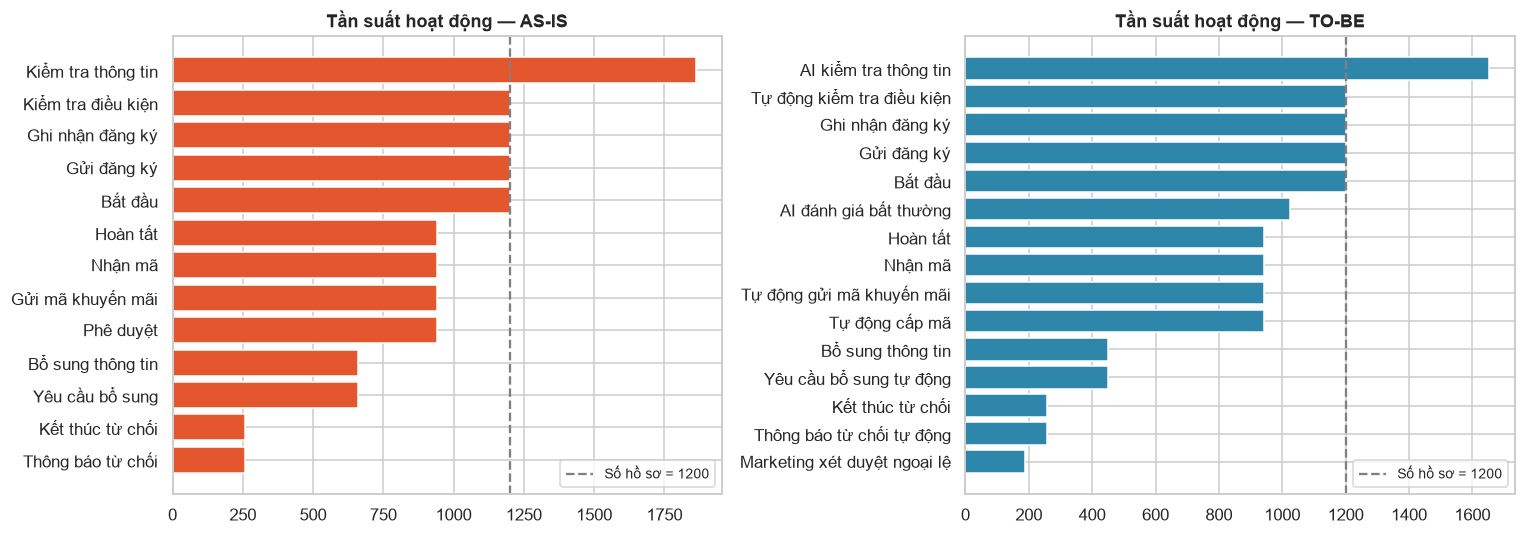

In [2]:
def activity_freq(df):
    return df["Activity"].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=False)
for ax, df, title, color in [(axes[0], asis, "AS-IS", PRIMARY),
                             (axes[1], tobe, "TO-BE", ACCENT)]:
    vc = activity_freq(df).sort_values()
    ax.barh(vc.index, vc.values, color=color)
    ax.axvline(df["Case ID"].nunique(), ls="--", color="gray",
               label=f"Số hồ sơ = {df['Case ID'].nunique()}")
    ax.set_title(f"Tần suất hoạt động — {title}", fontweight="bold")
    ax.legend(loc="lower right", fontsize=9)
plt.tight_layout(); plt.show()

**Nhóm em đọc biểu đồ này như sau:** Ở quy trình cũ (AS-IS), bước *Kiểm tra thông tin* chạy tới ≈1.861 lần trong khi chỉ có 1.200 hồ sơ → rõ ràng bị **làm lại nhiều**. Ở quy trình mới (TO-BE), *AI kiểm tra thông tin* giảm còn ≈1.651, và xuất hiện thêm bước *AI đánh giá bất thường* cùng *Marketing xét duyệt ngoại lệ* (chỉ dành cho các hồ sơ khó).

### 3.2. Bản đồ quy trình thực tế
Dưới đây là **bản đồ quy trình** do công cụ tự dựng từ dữ liệu — cho thấy các bước nối tiếp nhau thế nào và luồng nào phổ biến nhất (đường càng đậm, càng nhiều hồ sơ đi qua).



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




Bản đồ quy trình AS-IS (tần suất luồng):


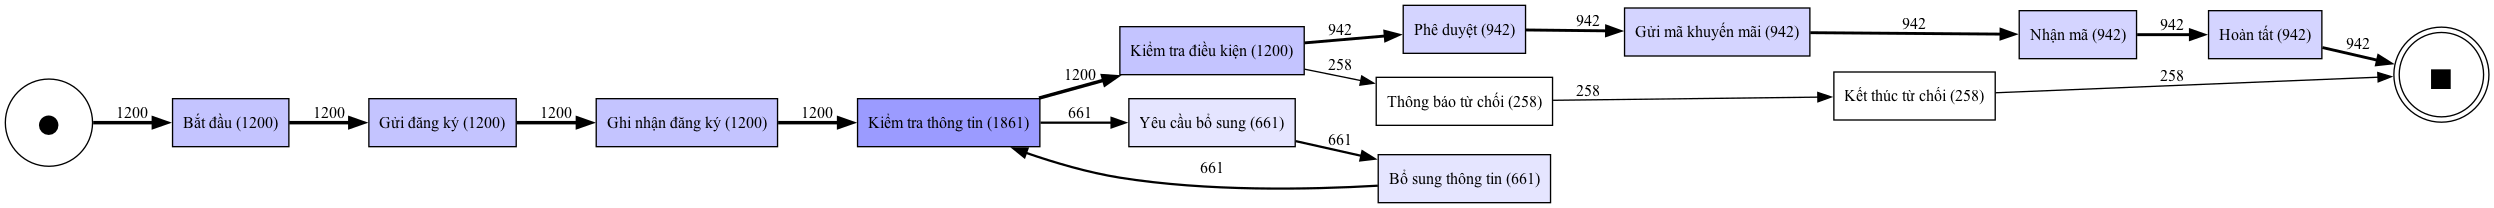

Bản đồ quy trình TO-BE (tần suất luồng):


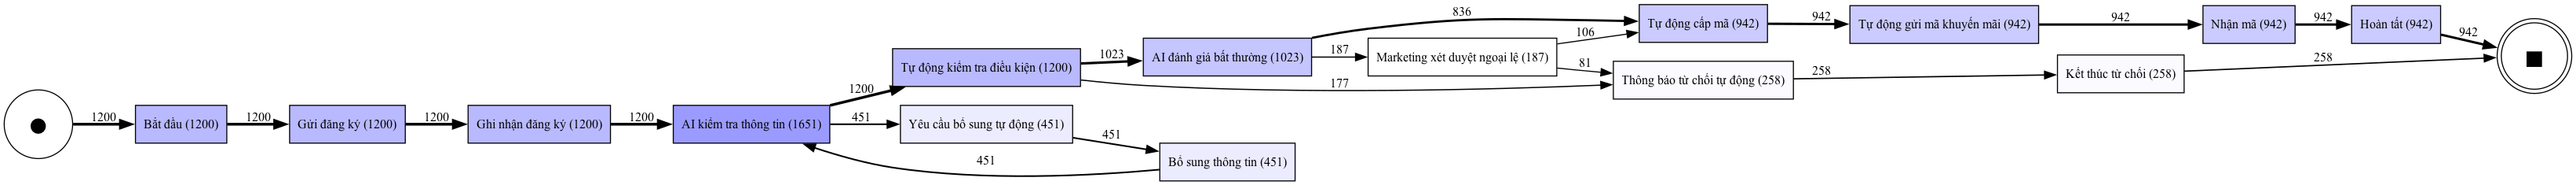


Top luồng (A -> B : số lần) — AS-IS
  Bắt đầu  ->  Gửi đăng ký : 1200
  Ghi nhận đăng ký  ->  Kiểm tra thông tin : 1200
  Gửi đăng ký  ->  Ghi nhận đăng ký : 1200
  Kiểm tra thông tin  ->  Kiểm tra điều kiện : 1200
  Gửi mã khuyến mãi  ->  Nhận mã : 942
  Kiểm tra điều kiện  ->  Phê duyệt : 942
  Nhận mã  ->  Hoàn tất : 942
  Phê duyệt  ->  Gửi mã khuyến mãi : 942


In [3]:
import pm4py

def to_event_log(df):
    d = df.rename(columns={
        "Case ID": "case:concept:name",
        "Activity": "concept:name",
        "Timestamp": "time:timestamp",
        "Resource": "org:resource",
    })
    return pm4py.format_dataframe(
        d, case_id="case:concept:name",
        activity_key="concept:name", timestamp_key="time:timestamp")

log_asis = to_event_log(asis)
log_tobe = to_event_log(tobe)

# DFG cho cả hai kịch bản + render bản đồ quy trình
dfg_a, sa, ea = pm4py.discover_dfg(log_asis)
dfg_b, sb, eb = pm4py.discover_dfg(log_tobe)

from IPython.display import Image, display
DFG_AS_IS = FIG_DIR / "dfg_as_is.png"
DFG_TO_BE = FIG_DIR / "dfg_to_be.png"
rendered = False
try:
    pm4py.save_vis_dfg(dfg_a, sa, ea, str(DFG_AS_IS))
    pm4py.save_vis_dfg(dfg_b, sb, eb, str(DFG_TO_BE))
    print("Bản đồ quy trình AS-IS (tần suất luồng):")
    display(Image(str(DFG_AS_IS)))
    print("Bản đồ quy trình TO-BE (tần suất luồng):")
    display(Image(str(DFG_TO_BE)))
    rendered = True
except Exception as e:
    print("(Graphviz chưa sẵn sàng, hiển thị dạng bảng:", e, ")")

# Top 8 luồng chuyển tiếp phổ biến nhất (luôn in để dự phòng)
top = sorted(dfg_a.items(), key=lambda x: -x[1])[:8]
print("\nTop luồng (A -> B : số lần) — AS-IS")
for (a, b), c in top:
    print(f"  {a}  ->  {b} : {c}")

### 3.3. Có bao nhiêu kiểu đi khác nhau?
Mỗi *kiểu đi* (variant) là một trình tự các bước. Nếu có vài kiểu chính nhưng lại kèm rất nhiều kiểu lạ hiếm gặp, nghĩa là quy trình **chưa được chuẩn hóa tốt**.

In [4]:
def variants_table(df, k=5):
    seq = (df.groupby("Case ID")["Activity"]
             .apply(lambda s: " → ".join(s)))
    vc = seq.value_counts()
    tbl = (vc.head(k).rename_axis("Variant").reset_index(name="Số hồ sơ"))
    tbl["%"] = (tbl["Số hồ sơ"] / len(seq) * 100).round(1)
    return tbl, vc

tbl_asis, vc_asis = variants_table(asis)
print(f"AS-IS: {len(vc_asis)} variants khác nhau. Top 5:")
for _, r in tbl_asis.iterrows():
    print(f"  [{r['Số hồ sơ']:>4} | {r['%']:>4}%] {r['Variant'][:90]}...")

AS-IS: 10 variants khác nhau. Top 5:
  [ 694 | 57.8%] Bắt đầu → Gửi đăng ký → Ghi nhận đăng ký → Kiểm tra thông tin → Kiểm tra điều kiện → Phê d...
  [ 138 | 11.5%] Bắt đầu → Gửi đăng ký → Ghi nhận đăng ký → Kiểm tra thông tin → Yêu cầu bổ sung → Bổ sung ...
  [ 113 |  9.4%] Bắt đầu → Gửi đăng ký → Ghi nhận đăng ký → Kiểm tra thông tin → Kiểm tra điều kiện → Thông...
  [  87 |  7.2%] Bắt đầu → Gửi đăng ký → Ghi nhận đăng ký → Kiểm tra thông tin → Yêu cầu bổ sung → Bổ sung ...
  [  64 |  5.3%] Bắt đầu → Gửi đăng ký → Ghi nhận đăng ký → Kiểm tra thông tin → Yêu cầu bổ sung → Bổ sung ...


## 4. Đo hiệu quả — thời gian đang bị "ăn" ở đâu?

### 4.1. Một hồ sơ mất bao lâu để xử lý xong?
Đây là **tổng thời gian** từ lúc khách bắt đầu đến lúc hoàn tất một hồ sơ.

In [5]:
def cycle_time_hours(df):
    g = df.groupby("Case ID")["Timestamp"]
    return ((g.max() - g.min()).dt.total_seconds() / 3600).rename("hours")

ct_asis = cycle_time_hours(asis)
ct_tobe = cycle_time_hours(tobe)

summary = pd.DataFrame({
    "AS-IS (giờ)": [ct_asis.mean(), ct_asis.median(), ct_asis.quantile(.9), ct_asis.max()],
    "TO-BE (giờ)": [ct_tobe.mean(), ct_tobe.median(), ct_tobe.quantile(.9), ct_tobe.max()],
}, index=["Trung bình", "Trung vị", "P90", "Lớn nhất"]).round(2)
summary["Giảm %"] = ((1 - summary["TO-BE (giờ)"] / summary["AS-IS (giờ)"]) * 100).round(1)
summary

,AS-IS (giờ),TO-BE (giờ),Giảm %
Trung bình,28.35,0.92,96.8
Trung vị,12.61,0.50,96.0
P90,60.44,2.02,96.7
Lớn nhất,297.73,6.02,98.0


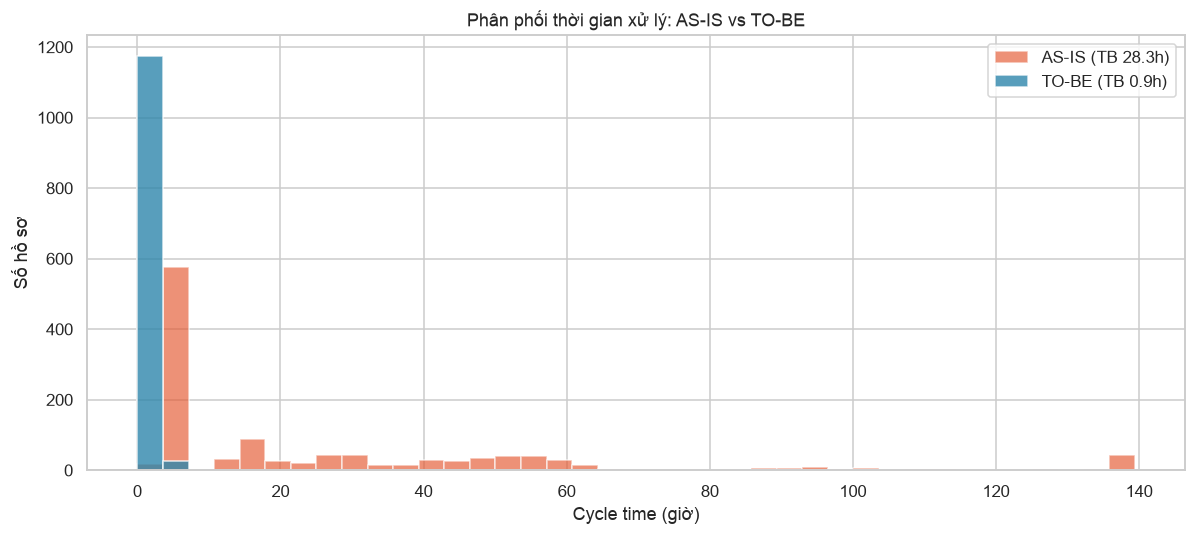

In [6]:
fig, ax = plt.subplots(figsize=(11, 5))
bins = np.linspace(0, max(ct_asis.quantile(.97), 6), 40)
ax.hist(ct_asis.clip(upper=bins[-1]), bins=bins, alpha=.65, color=PRIMARY,
        label=f"AS-IS (TB {ct_asis.mean():.1f}h)")
ax.hist(ct_tobe.clip(upper=bins[-1]), bins=bins, alpha=.8, color=ACCENT,
        label=f"TO-BE (TB {ct_tobe.mean():.1f}h)")
ax.set(xlabel="Cycle time (giờ)", ylabel="Số hồ sơ",
       title="Phân phối thời gian xử lý: AS-IS vs TO-BE")
ax.legend(); plt.tight_layout(); plt.show()

### 4.2. Điểm nghẽn — khách phải chờ lâu nhất sau bước nào?
Đây là phần quan trọng nhất để "biết điểm nghẽn ở đâu": nhóm em đo khoảng thời gian giữa hai bước liên tiếp trong cùng một hồ sơ. Bước nào mà **sau nó khách phải chờ lâu** chính là điểm nghẽn.

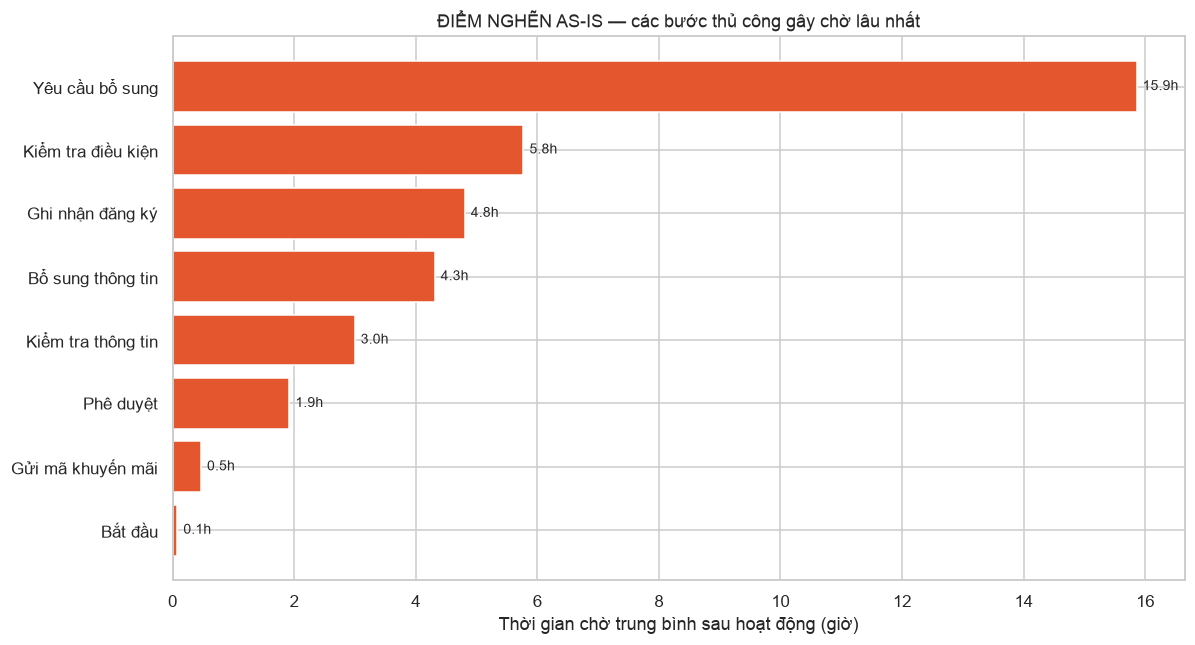

Điểm nghẽn lớn nhất: Yêu cầu bổ sung (15.9h chờ)


In [7]:
def waiting_after(df):
    d = df.copy()
    d["next_ts"] = d.groupby("Case ID")["Timestamp"].shift(-1)
    d["wait_h"] = (d["next_ts"] - d["Timestamp"]).dt.total_seconds() / 3600
    return d.dropna(subset=["wait_h"]).groupby("Activity")["wait_h"].mean().sort_values(ascending=False)

wa_asis = waiting_after(asis)
wa_tobe = waiting_after(tobe)

fig, ax = plt.subplots(figsize=(11, 6))
top_asis = wa_asis.head(8).sort_values()
ax.barh(top_asis.index, top_asis.values, color=PRIMARY)
for i, v in enumerate(top_asis.values):
    ax.text(v + .1, i, f"{v:.1f}h", va="center", fontsize=9)
ax.set(xlabel="Thời gian chờ trung bình sau hoạt động (giờ)",
       title="ĐIỂM NGHẼN AS-IS — các bước thủ công gây chờ lâu nhất")
plt.tight_layout(); plt.show()
print("Điểm nghẽn lớn nhất:", top_asis.index[-1], f"({top_asis.max():.1f}h chờ)")

**Phát hiện chính của nhóm em:** các điểm nghẽn đều rơi vào **những bước làm tay của Marketing/CSKH** — *Yêu cầu bổ sung*, *Kiểm tra điều kiện*, *Phê duyệt*. Đây đúng là những bước nên giao cho AI / tự động hóa.

### 4.3. Làm lại nhiều không? Ai đang gánh việc?

AS-IS: 32.8% hồ sơ phải kiểm tra lại — tổng 1861 lần kiểm tra
TO-BE: 32.8% hồ sơ phải kiểm tra lại — tổng 1651 lần kiểm tra


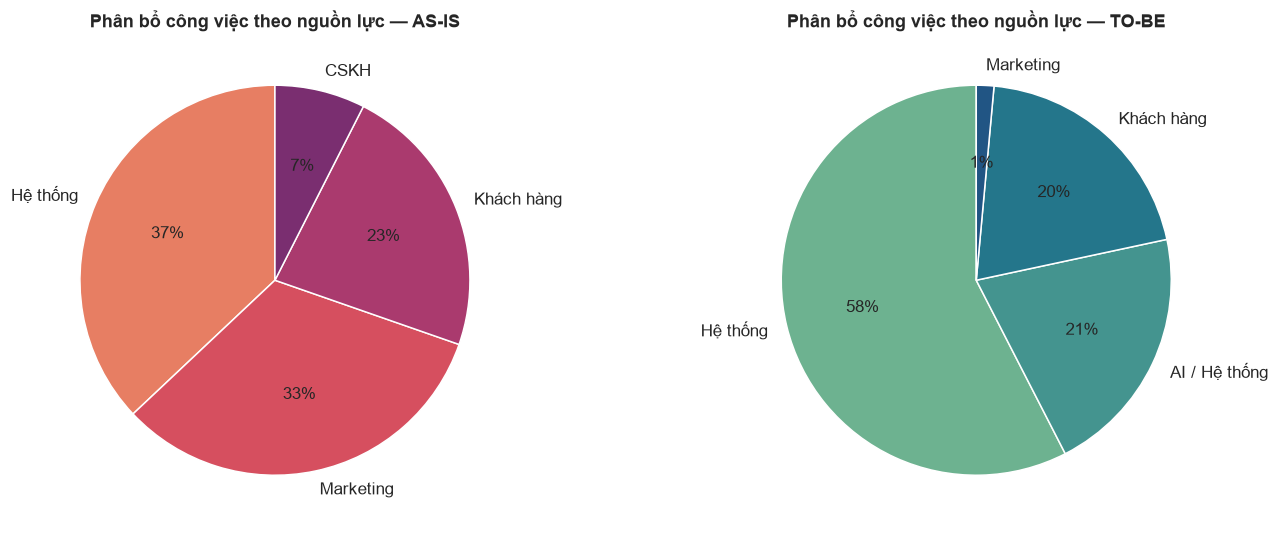

In [8]:
def rework_rate(df):
    kt = df[df["Activity"].str.contains("iểm tra thông tin")]
    rc = kt.groupby("Case ID").size()
    return (rc > 1).mean() * 100, len(kt)

r_asis, n_asis = rework_rate(asis)
r_tobe, n_tobe = rework_rate(tobe)
print(f"AS-IS: {r_asis:.1f}% hồ sơ phải kiểm tra lại — tổng {n_asis} lần kiểm tra")
print(f"TO-BE: {r_tobe:.1f}% hồ sơ phải kiểm tra lại — tổng {n_tobe} lần kiểm tra")

# Tải theo nguồn lực
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, df, title, color in [(axes[0], asis, "AS-IS", PRIMARY),
                             (axes[1], tobe, "TO-BE", ACCENT)]:
    vc = df["Resource"].value_counts()
    ax.pie(vc.values, labels=vc.index, autopct="%1.0f%%", startangle=90,
           colors=sns.color_palette("flare" if title=="AS-IS" else "crest", len(vc)))
    ax.set_title(f"Phân bổ công việc theo nguồn lực — {title}", fontweight="bold")
plt.tight_layout(); plt.show()

**Nhận xét của nhóm em:** Ở quy trình cũ, Marketing gánh khoảng 1/3 khối lượng (≈4.003 lượt thao tác). Ở quy trình mới, phần việc này chuyển sang **AI / Hệ thống**; Marketing chỉ còn ≈187 lượt (chỉ xử lý các trường hợp ngoại lệ) → giải phóng nhân lực để làm việc có giá trị cao hơn.

## 5. Quy trình mới có AI (TO-BE) — đặt AI vào đúng điểm nghẽn

Từ những gì phân tích ở Phần 3–4, nhóm em đưa AI vào **đúng các bước đang gây nghẽn**:

| Bước cũ (làm tay) | Đang nghẽn thế nào | Nhóm em thay bằng |
|-----------------------|-----------|--------------------------|
| Kiểm tra thông tin (Marketing) | làm lại 32,8%, chờ ~3h | **AI kiểm tra thông tin** — tự đọc & đối chiếu |
| Kiểm tra điều kiện (Marketing) | chờ ~5,8h | **Tự động kiểm tra điều kiện** theo quy tắc |
| Phê duyệt (Marketing) | chờ ~1,9h | **AI đánh giá bất thường** + tự động cấp mã; chỉ hồ sơ nghi ngờ mới chuyển người |
| Yêu cầu bổ sung (làm tay) | chờ ~15,9h | **Yêu cầu bổ sung tự động** ngay lập tức |
| Xử lý ngoại lệ | — | **Marketing xét duyệt ngoại lệ** (vẫn có con người kiểm soát) |

**Nguyên tắc nhóm em theo:** AI lo phần lớn các hồ sơ thông thường; con người tập trung vào ngoại lệ. Nhờ vậy vừa **nhanh** vừa **kiểm soát được rủi ro**.


In [9]:
# Minh chứng bằng số: cột AI Review Required (chỉ có ở TO-BE)
if "AI Review Required" in tobe.columns:
    rev = tobe.groupby("Case ID")["AI Review Required"].first().value_counts()
    print("Hồ sơ cần người xét duyệt (ngoại lệ):", rev.to_dict())
    pct = rev.get("Có", 0) / rev.sum() * 100
    print(f"=> AI tự động hóa hoàn toàn ~{100-pct:.1f}% hồ sơ, chỉ {pct:.1f}% cần người.")

Hồ sơ cần người xét duyệt (ngoại lệ): {'Không': 1013, 'Có': 187}
=> AI tự động hóa hoàn toàn ~84.4% hồ sơ, chỉ 15.6% cần người.


## 6. So sánh trước ↔ sau — kết quả bằng con số
Sau đây là phần nhóm em tâm đắc nhất: những con số cho thấy quy trình mới tốt hơn bao nhiêu.

In [10]:
kpis = pd.DataFrame({
    "Chỉ số": ["Cycle time TB (giờ)", "Cycle time P90 (giờ)",
               "Sự kiện/hồ sơ (TB)", "Khối lượng việc Marketing (sự kiện)",
               "Tỷ lệ tự động hóa (%)"],
    "AS-IS": [ct_asis.mean(),
              ct_asis.quantile(.9),
              len(asis)/asis["Case ID"].nunique(),
              int((asis["Resource"]=="Marketing").sum()),
              0.0],
    "TO-BE": [ct_tobe.mean(),
              ct_tobe.quantile(.9),
              len(tobe)/tobe["Case ID"].nunique(),
              int((tobe["Resource"]=="Marketing").sum()),
              float((tobe["Resource"]=="AI / Hệ thống").any()) and
                  round((tobe["Resource"].isin(["AI / Hệ thống","Hệ thống"]).sum())/len(tobe)*100,1)],
})
kpis["Cải thiện"] = kpis.apply(
    lambda r: f"{(1 - r['TO-BE']/r['AS-IS'])*100:.0f}% giảm"
    if r["AS-IS"] not in (0,) and r["Chỉ số"]!="Tỷ lệ tự động hóa (%)"
    else "tăng", axis=1)
kpis.round(2)

,Chỉ số,AS-IS,TO-BE,Cải thiện
0,Cycle time TB (giờ),28.35,0.92,97% giảm
1,Cycle time P90 (giờ),60.44,2.02,97% giảm
2,Sự kiện/hồ sơ (TB),10.22,10.71,-5% giảm
3,Khối lượng việc Marketing (sự kiện),4003.00,187.00,95% giảm
4,Tỷ lệ tự động hóa (%),0.00,78.40,tăng


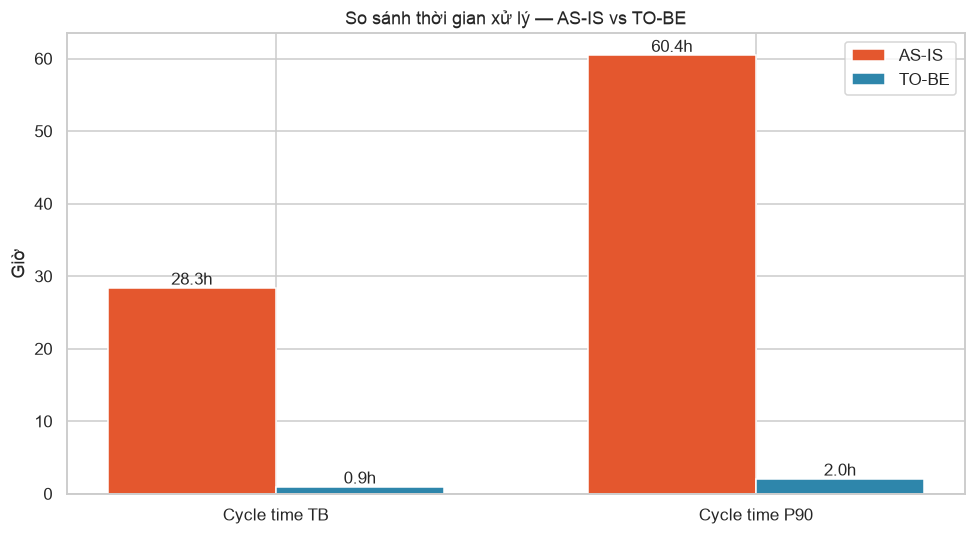

>> Thời gian xử lý trung bình nhanh hơn ~31 lần (28.3h -> 0.9h).


In [11]:
# Biểu đồ cột so sánh cycle time trung bình & P90
fig, ax = plt.subplots(figsize=(9, 5))
labels = ["Cycle time TB", "Cycle time P90"]
asis_v = [ct_asis.mean(), ct_asis.quantile(.9)]
tobe_v = [ct_tobe.mean(), ct_tobe.quantile(.9)]
x = np.arange(len(labels)); w = .35
b1 = ax.bar(x-w/2, asis_v, w, label="AS-IS", color=PRIMARY)
b2 = ax.bar(x+w/2, tobe_v, w, label="TO-BE", color=ACCENT)
ax.bar_label(b1, fmt="%.1fh"); ax.bar_label(b2, fmt="%.1fh")
ax.set_xticks(x); ax.set_xticklabels(labels)
ax.set(ylabel="Giờ", title="So sánh thời gian xử lý — AS-IS vs TO-BE")
ax.legend(); plt.tight_layout(); plt.show()

print(f">> Thời gian xử lý trung bình nhanh hơn ~{ct_asis.mean()/ct_tobe.mean():.0f} lần "
      f"({ct_asis.mean():.1f}h -> {ct_tobe.mean():.1f}h).")

## 7. Kết luận & Đề xuất

### Kết quả chính (bằng con số)
- **Thời gian xử lý trung bình giảm ~97%** (28,3 giờ → 0,9 giờ) — tức **nhanh hơn khoảng 31 lần**.
- **Điểm nghẽn** được tìm ra một cách khách quan bằng Process Mining: nằm ở các bước làm tay *Yêu cầu bổ sung*, *Kiểm tra điều kiện*, *Phê duyệt*.
- **Đặt AI đúng điểm nghẽn** → tự động hóa phần lớn hồ sơ, con người chỉ lo ngoại lệ.
- **Giảm tải cho Marketing**: từ ~4.003 xuống còn ~187 lượt thao tác.

### Bài học về quản trị vận hành
1. **Đo trước, cải tiến sau.** Có dữ liệu thật thì quyết định mới chắc chắn, không phỏng đoán.
2. **AI hiệu quả nhất khi gắn đúng chỗ nghẽn**, chứ không phải rải đều khắp nơi.
3. **Vẫn giữ con người trong vòng lặp** để cân bằng giữa tốc độ và kiểm soát rủi ro.

### Đề xuất lộ trình áp dụng
1. Giai đoạn 1 — đưa AI vào kiểm tra thông tin & điều kiện (chỗ nghẽn lớn nhất).
2. Giai đoạn 2 — tự động cấp/gửi mã, cảnh báo bất thường.
3. Giai đoạn 3 — theo dõi liên tục bằng Process Mining để kịp phát hiện quy trình bị lệch.

---
*Nhóm em xin chân thành cảm ơn thầy/cô và các bạn đã lắng nghe!*

*(Phân tích thực hiện bằng Python + PM4Py trên dữ liệu thực tế: 1.200 hồ sơ cho mỗi kịch bản.)*
